In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import math
import torch.nn.functional as F

In [2]:
img_size = 28

transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

batch_size = 128

train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)

shoe_data = [train_dataset.data[i] for i in range(len(train_dataset.targets)) if train_dataset.targets[i] in [5,7,9]]
not_shoe_data = [train_dataset.data[i] for i in range(len(train_dataset.targets)) if train_dataset.targets[i] not in [5,7,9]]

train_shoe_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
train_shoe_dataset.data = shoe_data[:500]
train_shoe_dataset.targets = torch.ones(len(train_shoe_dataset.data)).long()[:2000]

trainloader = DataLoader(
    train_shoe_dataset, 
    batch_size=batch_size, 
    shuffle=True,
)

len(train_shoe_dataset.targets)

500

In [3]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class uNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 10)

    def extract_features(self, x):
        return self.features(x)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.GroupNorm(32, 64), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.GroupNorm(32, 128), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.GroupNorm(32, 256), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.GroupNorm(32, 512), nn.ReLU(), nn.MaxPool2d(2),
            
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )
        
        self.time_mlp = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128)
        )
        
        self.fc = nn.Linear(512 + 128, 2)

    def forward(self, x, t):
        img_feats = self.features(x)
        
        if t.dim() == 1:
            t = t.unsqueeze(-1).float()
            
        time_feats = self.time_mlp(t)
        
        combined = torch.cat([img_feats, time_feats], dim=1)
        return self.fc(combined)

In [4]:
device = "cuda"
n_steps = 500
img_size = 28


diffusionModel = uNet().to(device)
binaryClassifierModel = Net().to(device)
classifierModel = Classifier().to(device)


state_dict = torch.load("fashion_mnist_unet.pth", map_location=device, weights_only=True)
diffusionModel.load_state_dict(state_dict)
diffusionModel.eval()

state_dict = torch.load("fashion_classifier_net.pth", map_location=device, weights_only=True)
binaryClassifierModel.load_state_dict(state_dict)
binaryClassifierModel.eval()

state_dict = torch.load("fashion_mnist_cnn.pth", map_location=device, weights_only=True)
classifierModel.load_state_dict(state_dict)
classifierModel.eval()

1

1

In [89]:
def sample(samples, model, s):
    xt = torch.randn(samples, 1, img_size, img_size).to(device)
    for t in reversed(range(n_steps)):
        if t % 100 == 0:
            print(t)
        t_tensor = torch.tensor([t] * samples, device=device)
        
        eps_pred = diffusionModel(xt, t_tensor.float() / n_steps)
        
        alpha_t = alpha[t]
        alpha_bar_t = alpha_bar[t]
        var = beta[t]
    
        mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
        with torch.enable_grad():
            dre_xt = xt.detach().clone().requires_grad_(True)
            
            logits = binaryClassifierModel(dre_xt, t_tensor) 
            log_probs = F.log_softmax(logits, dim=1)
            
            r = log_probs[:, 1]  - log_probs[:, 0]
            
            guide_score = torch.autograd.grad(
                outputs=r.sum(),
                inputs=dre_xt
            )[0]
        
        mean = mean + s * var * guide_score
    
        if t > 0:
            noise = torch.randn_like(xt)
            xt = mean + torch.sqrt(var) * noise
        else:
            xt = mean
    return xt

In [137]:
beta = torch.linspace(1e-4, 0.02, n_steps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

scores = []

s_values = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 2.5]
samples = []

for s in s_values:
    
    diffusionModel.eval()
    with torch.no_grad():
    
        xt = sample(500, diffusionModel, s)

        # xt = xt[:20]
        # xt = xt.clamp(-1, 1) * 0.5 + 0.5
        # xt = xt.cpu()

    samples.append(xt)
        

400
300
200
100
0
400
300
200
100
0
400
300
200
100
0
400
300
200
100
0
400
300
200
100
0
400
300
200
100
0
400
300
200
100
0
400
300
200
100
0


In [141]:
samples = torch.load("samples.pt")

In [148]:
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

idx = ((dataset.targets == 5) | (dataset.targets == 7) | (dataset.targets == 9)).nonzero(as_tuple=True)[0]

real_images = torch.stack([
    dataset[i][0] for i in idx
]).to(device)

real_images.shape

torch.Size([3000, 1, 28, 28])

In [202]:
def knn_radius(features, k=10):
    dists = torch.cdist(features, features)
    dists.fill_diagonal_(float("inf"))
    return dists.kthvalue(k, dim=1).values


def precision(real_feats, fake_feats, r_real):
    d = torch.cdist(fake_feats, real_feats)
    return (d <= r_real.unsqueeze(0)).any(dim=1).float().mean().item()


def recall(real_feats, fake_feats, r_fake):
    d = torch.cdist(real_feats, fake_feats)
    return (d <= r_fake.unsqueeze(0)).any(dim=1).float().mean().item()

import torch
import numpy as np
from scipy import linalg

def compute_fid(real_feats, fake_feats, eps=1e-6):
    """
    real_feats, fake_feats: [N, D] torch tensors
    """
    real = real_feats.detach().cpu().numpy()
    fake = fake_feats.detach().cpu().numpy()

    mu_r = real.mean(axis=0)
    mu_f = fake.mean(axis=0)

    sigma_r = np.cov(real, rowvar=False)
    sigma_f = np.cov(fake, rowvar=False)

    diff = mu_r - mu_f

    covmean, _ = linalg.sqrtm(sigma_r @ sigma_f, disp=False)
    if not np.isfinite(covmean).all():
        covmean = linalg.sqrtm((sigma_r + eps*np.eye(sigma_r.shape[0])) @
                               (sigma_f + eps*np.eye(sigma_f.shape[0])))

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma_r + sigma_f - 2 * covmean)
    return float(fid)


In [203]:
metrics = []
for sample, s in zip(samples, [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 2.5]):
    print("...")
    perm = torch.randperm(real_images.shape[0])[:sample.shape[0]]
    p, r, fid = 0, 0, 0
    for i in range(10):
        real_feats = classifierModel.features(real_images[perm])
        fake_feats = classifierModel.features(sample)
        
        r_real = knn_radius(real_feats)
        r_fake = knn_radius(fake_feats)
        
        p += precision(real_feats, fake_feats, r_real)
        r += recall(real_feats, fake_feats, r_fake)
        fid += compute_fid(real_feats, fake_feats)
    fid /= 10
    p /= 10
    r /= 10
    metrics.append((s, fid, p, r, (2 * p * r) / (p + r)))

...
...
...
...
...
...
...
...


In [204]:
m = torch.tensor(metrics)
m

tensor([[ 0.0000, 69.7016,  0.3880,  0.9900,  0.5575],
        [ 0.2500, 30.3538,  0.6920,  0.9740,  0.8091],
        [ 0.5000,  9.4522,  0.8960,  0.9880,  0.9398],
        [ 0.7500,  6.4647,  0.9720,  0.9520,  0.9619],
        [ 1.0000,  8.4826,  0.9920,  0.9100,  0.9492],
        [ 1.5000,  9.6084,  0.9940,  0.8900,  0.9391],
        [ 2.0000, 14.0333,  0.9940,  0.8200,  0.8987],
        [ 2.5000, 14.0098,  0.9880,  0.7880,  0.8767]])

(0.0, 100.0)

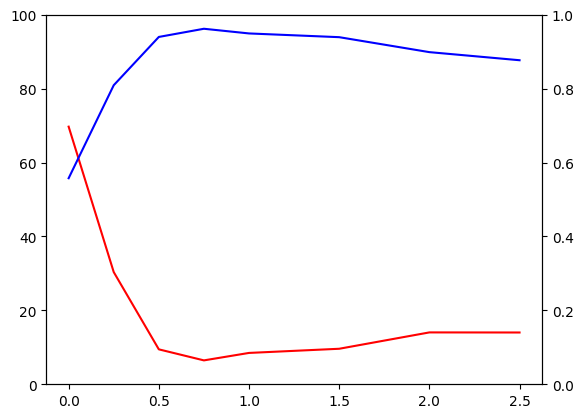

In [205]:
fig, ax1 = plt.subplots()
ax1.plot(m[:, 0], m[:, 1], color="red")
ax2 = ax1.twinx()
ax2.plot(m[:, 0], m[:, 4], color="blue")
ax2.set_ylim(0,1)
ax1.set_ylim(0, 100)